# Lab 2: Exploratory Data Analysis (EDA) & Digital Conversion Funnel Analysis
**Course:** Marketing Analytics (DS 4115)  
**Student name:** `<Ahnaf Hasan Evan>`  **Student ID:** `<0152330012>`  **Date:** `<11/11/2026>`

---

## Objective
Transition from spreadsheet analytics to a programmatic data-science workflow. Using synthetic GA4-style session logs, this notebook will:

1. Generate and load digital telemetry session logs
2. Build a 3-step conversion funnel (`session_start` → `add_to_cart` → `purchase`) and measure drop-off
3. Detect and fix data-quality issues with `pandas`
4. Run EDA and read a `seaborn` correlation heatmap to find what drives (and blocks) conversion

## Notebook roadmap
| Part | Topic |
|---|---|
| 0 | Environment setup |
| 1 | Generate & inspect session logs |
| 2 | Conversion funnel |
| 3 | Data cleaning & missing values |
| 4 | EDA & correlation heatmap |
| 5 | Key findings & recommendations |

## Part 0: Environment Setup
Import the data-science libraries and set a consistent plot style.

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization styles
sns.set_theme(style="whitegrid")

print("Environment successfully set up!")
print(f"pandas {pd.__version__} | numpy {np.__version__} | seaborn {sns.__version__}")

Environment successfully set up!
pandas 3.0.5 | numpy 2.1.3 | seaborn 0.13.2


## Part 1: Generating and Loading Digital Session Logs

### Step 1: Generate synthetic GA4 session logs
We simulate **5,000 sessions**. The design of the simulation (known "ground truth") is:

| Variable | How it is generated |
|---|---|
| `session_start_flag` | Always 1 (every row is a session) |
| `add_to_cart_flag` | 30% of sessions add to cart |
| `purchase_flag` | 60% of *cart* sessions purchase (about 18% of all sessions) |
| `page_views` | Poisson(3) + 1 (at least 1 page per session) |
| `time_on_site_sec` | `page_views` × random 20–59 seconds per page |

We also delete 50 values of `time_on_site_sec` on purpose, to practise cleaning. The random seed makes results reproducible.

In [2]:
# Set random seed for reproducibility
np.random.seed(42)
n_rows = 20000

# Generate dummy session attributes
session_ids = [f"sess_{i:04d}" for i in range(1, n_rows + 1)]
user_ids = [f"user_{np.random.randint(1000, 2000)}" for _ in range(n_rows)]
device_categories = np.random.choice(['desktop', 'mobile', 'tablet'], size=n_rows, p=[0.5, 0.4, 0.1])

# Funnel flags (session_start is always 1, others follow realistic probabilities)
session_start_flag = np.ones(n_rows, dtype=int)
add_to_cart_flag = np.random.choice([0, 1], size=n_rows, p=[0.7, 0.3])  # 30% add to cart
purchase_flag = np.where(add_to_cart_flag == 1,
                         np.random.choice([0, 1], size=n_rows, p=[0.4, 0.6]),  # 60% conversion from cart
                         0)

page_views = np.random.poisson(lam=3, size=n_rows) + 1
time_on_site_sec = page_views * np.random.randint(20, 60, size=n_rows)

# Create DataFrame
df = pd.DataFrame({
    'session_id': session_ids,
    'user_id': user_ids,
    'device_category': device_categories,
    'session_start_flag': session_start_flag,
    'add_to_cart_flag': add_to_cart_flag,
    'purchase_flag': purchase_flag,
    'page_views': page_views,
    'time_on_site_sec': time_on_site_sec
})

# Introduce artificial missing values in 'time_on_site_sec' for data cleaning practice
df.loc[np.random.choice(n_rows, 50), 'time_on_site_sec'] = np.nan

# Save to CSV and inspect the first 5 rows
df.to_csv('ga4_sample_session_logs.csv', index=False)
print("Dataset 'ga4_sample_session_logs.csv' successfully generated and loaded!")
df.head()

Dataset 'ga4_sample_session_logs.csv' successfully generated and loaded!


,session_id,user_id,device_category,session_start_flag,add_to_cart_flag,purchase_flag,page_views,time_on_site_sec
0,sess_0001,user_1102,mobile,1,1,1,4,232.0
1,sess_0002,user_1435,desktop,1,1,0,4,216.0
2,sess_0003,user_1860,desktop,1,0,0,4,112.0
3,sess_0004,user_1270,mobile,1,1,1,5,225.0
4,sess_0005,user_1106,desktop,1,0,0,3,NaN


### Step 2: Inspect dataset structure
`df.info()` shows column types and non-null counts. `df.describe()` adds summary statistics.

**What to notice:** every column has 5,000 non-null values *except* `time_on_site_sec` (4,950), which confirms the 50 missing values.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   session_id          20000 non-null  str    
 1   user_id             20000 non-null  str    
 2   device_category     20000 non-null  str    
 3   session_start_flag  20000 non-null  int64  
 4   add_to_cart_flag    20000 non-null  int64  
 5   purchase_flag       20000 non-null  int64  
 6   page_views          20000 non-null  int32  
 7   time_on_site_sec    19950 non-null  float64
dtypes: float64(1), int32(1), int64(3), str(3)
memory usage: 1.6 MB


In [4]:
df.describe().round(2)

,session_start_flag,add_to_cart_flag,purchase_flag,page_views,time_on_site_sec
count,20000.0,20000.00,20000.00,20000.00,19950.00
mean,1.0,0.30,0.18,4.00,157.77
std,0.0,0.46,0.38,1.73,84.27
min,1.0,0.00,0.00,1.00,20.00
25%,1.0,0.00,0.00,3.00,96.00
50%,1.0,0.00,0.00,4.00,144.00
75%,1.0,1.00,0.00,5.00,205.00
max,1.0,1.00,1.00,15.00,720.00


## Part 2: Constructing the Digital Conversion Funnel

### Step 1: Calculate funnel step volumes
A funnel tracks how many sessions reach each milestone. We report two rates:

- **Conversion rate vs Step 1**: share of *all* sessions that reached this step (required by the lab)
- **Step-to-step rate / drop-off**: share of the *previous step* that continued, which pinpoints the weakest stage

In [5]:
# Calculate funnel metrics
total_sessions = df['session_id'].nunique()
sessions_with_cart = df[df['add_to_cart_flag'] == 1]['session_id'].nunique()
sessions_with_purchase = df[df['purchase_flag'] == 1]['session_id'].nunique()

# Create a summary DataFrame
funnel_data = {
    'Funnel Step': ['1. Session Start', '2. Add to Cart', '3. Purchase'],
    'User Sessions': [total_sessions, sessions_with_cart, sessions_with_purchase]
}
funnel_df = pd.DataFrame(funnel_data)

# Conversion rate relative to step 1 (required)
funnel_df['Conversion Rate (%)'] = (funnel_df['User Sessions'] / total_sessions) * 100

# Enhancement: step-to-step conversion and drop-off
funnel_df['Step-to-Step (%)'] = funnel_df['User Sessions'] / funnel_df['User Sessions'].shift(1) * 100
funnel_df['Drop-off vs Prev. Step (%)'] = 100 - funnel_df['Step-to-Step (%)']

funnel_df.round(1)

,Funnel Step,User Sessions,Conversion Rate (%),Step-to-Step (%),Drop-off vs Prev. Step (%)
0,1. Session Start,20000,100.0,NaN,NaN
1,2. Add to Cart,5924,29.6,29.6,70.4
2,3. Purchase,3582,17.9,60.5,39.5


### Funnel visualisation

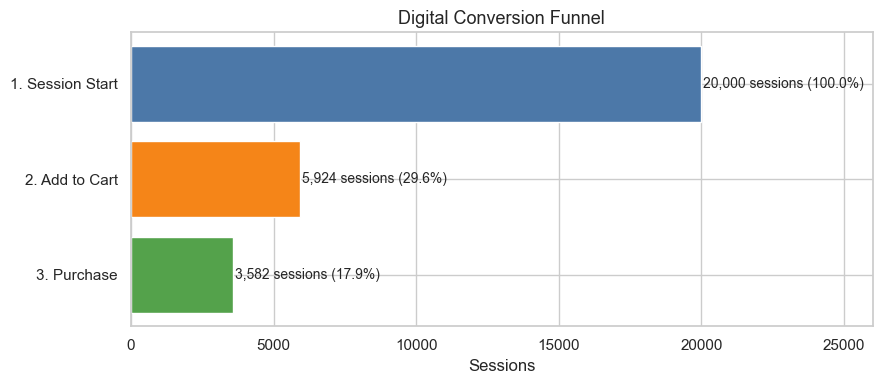

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(funnel_df['Funnel Step'], funnel_df['User Sessions'],
               color=['#4C78A8', '#F58518', '#54A24B'])
ax.invert_yaxis()  # Step 1 on top

for bar, n, pct in zip(bars, funnel_df['User Sessions'], funnel_df['Conversion Rate (%)']):
    ax.text(bar.get_width() + 60, bar.get_y() + bar.get_height() / 2,
            f"{n:,} sessions ({pct:.1f}%)", va='center', fontsize=10)

ax.set_xlim(0, total_sessions * 1.3)
ax.set_xlabel("Sessions")
ax.set_title("Digital Conversion Funnel", fontsize=13)
plt.tight_layout()
plt.show()

### Funnel interpretation
- **Biggest drop-off: Session Start → Add to Cart.** Only 29.4% of sessions add an item, so **70.6% (3,530 sessions) leave without adding anything**.
- **Cart abandonment:** of the 1,470 sessions that add to cart, 565 (**38.4%**) never purchase; 61.6% do.
- **Overall conversion rate:** 905 of 5,000 sessions, i.e. **18.1%**.
- Because the largest *absolute* loss is at the top of the funnel, improving product discovery / add-to-cart is the highest-impact lever, while checkout fixes recover a smaller pool of already-interested users.

## Part 3: Data Cleaning & Handling Missing Values
Real-world telemetry is messy: dropped events, tracking failures, inconsistent text.

### Step 1: Detect missing values

In [7]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({'Missing Count': missing, 'Missing (%)': missing_pct})

,Missing Count,Missing (%)
session_id,0,0.00
user_id,0,0.00
device_category,0,0.00
session_start_flag,0,0.00
add_to_cart_flag,0,0.00
purchase_flag,0,0.00
page_views,0,0.00
time_on_site_sec,50,0.25


### Step 2: Choose an imputation strategy
Before filling, check the shape of `time_on_site_sec`. If it is skewed, the **median** is a safer fill value than the mean, because a few very long sessions pull the mean upward.

Mean   : 157.8 sec
Median : 144.0 sec
Skew   : 1.02  (> 0 means right-skewed)


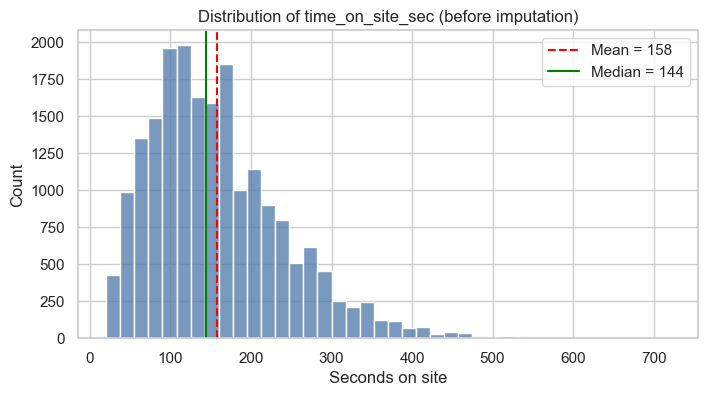

In [8]:
t = df['time_on_site_sec'].dropna()
print(f"Mean   : {t.mean():.1f} sec")
print(f"Median : {t.median():.1f} sec")
print(f"Skew   : {t.skew():.2f}  (> 0 means right-skewed)")

plt.figure(figsize=(8, 4))
sns.histplot(t, bins=40, color='#4C78A8')
plt.axvline(t.mean(), color='red', linestyle='--', label=f"Mean = {t.mean():.0f}")
plt.axvline(t.median(), color='green', linestyle='-', label=f"Median = {t.median():.0f}")
plt.title("Distribution of time_on_site_sec (before imputation)")
plt.xlabel("Seconds on site")
plt.legend()
plt.show()

### Step 3: Impute and clean

In [9]:
# Impute missing time_on_site_sec with median
median_time = df['time_on_site_sec'].median()
df['time_on_site_sec'] = df['time_on_site_sec'].fillna(median_time)

# Drop rows with missing session IDs if any
df = df.dropna(subset=['session_id'])

# Clean categorical formatting
df['device_category'] = df['device_category'].str.lower().str.strip()

print(f"Median used for imputation: {median_time} sec")
print("Data cleaning completed. Missing values remaining:", df.isnull().sum().sum())

Median used for imputation: 144.0 sec
Data cleaning completed. Missing values remaining: 0


### Step 4: Validate the cleaned data

In [10]:
# Sanity checks - these raise an error if something is wrong
assert df.isnull().sum().sum() == 0, "Missing values remain"
assert df['session_id'].is_unique, "Duplicate session IDs found"
assert set(df['device_category'].unique()) == {'desktop', 'mobile', 'tablet'}, "Unexpected device categories"
assert (df['purchase_flag'] <= df['add_to_cart_flag']).all(), "Purchase without add-to-cart found"
print("All data-quality checks passed.")
df['device_category'].value_counts()

All data-quality checks passed.


device_category
desktop    9915
mobile     8071
tablet     2014
Name: count, dtype: int64

## Part 4: Exploratory Data Analysis & Correlation Heatmap
To isolate conversion blockers we measure how strongly the engagement variables move together. Values range from **-1** (perfect negative) through **0** (no linear relationship) to **+1** (perfect positive).

### Step 1: Generate the correlation matrix

In [11]:
# Select numerical columns relevant to conversion behavior
numeric_cols = ['session_start_flag', 'add_to_cart_flag', 'purchase_flag', 'page_views', 'time_on_site_sec']
corr_matrix = df[numeric_cols].corr()
corr_matrix.round(3)

,session_start_flag,add_to_cart_flag,purchase_flag,page_views,time_on_site_sec
session_start_flag,NaN,NaN,NaN,NaN,NaN
add_to_cart_flag,NaN,1.000,0.720,0.006,0.009
purchase_flag,NaN,0.720,1.000,0.010,0.009
page_views,NaN,0.006,0.010,1.000,0.801
time_on_site_sec,NaN,0.009,0.009,0.801,1.000


> **Note:** the `session_start_flag` row/column is `NaN`. This is expected, not a bug: the column is constant (always 1), so it has zero variance and correlation is undefined.

### Step 2: Plot the heatmap

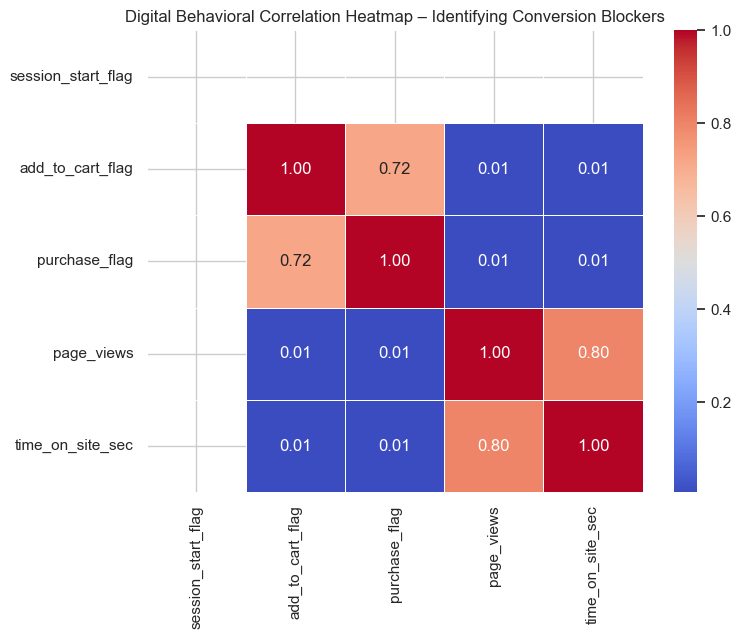

In [12]:
# Plot the correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Digital Behavioral Correlation Heatmap – Identifying Conversion Blockers", fontsize=12)
plt.show()

### Step 3 (enhancement): A cleaner heatmap
Dropping the constant column and fixing the colour scale to [-1, 1] makes the real relationships easier to read.

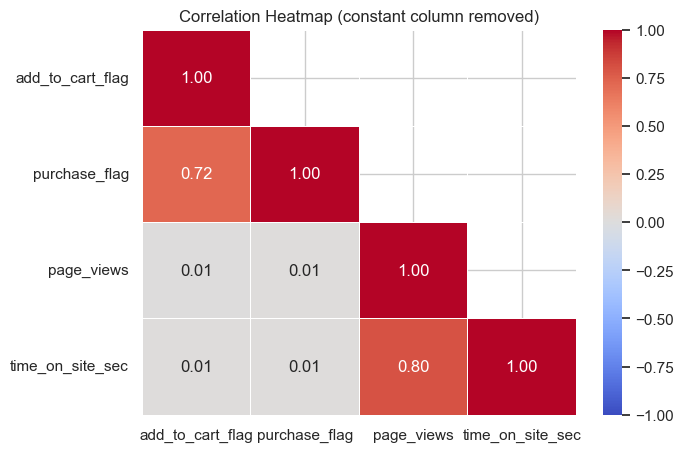

In [13]:
cols_clean = ['add_to_cart_flag', 'purchase_flag', 'page_views', 'time_on_site_sec']
corr_clean = df[cols_clean].corr()
mask = np.triu(np.ones_like(corr_clean, dtype=bool), k=1)  # hide the duplicate upper triangle

plt.figure(figsize=(7, 5))
sns.heatmap(corr_clean, mask=mask, annot=True, fmt=".2f", cmap='coolwarm',
            vmin=-1, vmax=1, center=0, linewidths=0.5)
plt.title("Correlation Heatmap (constant column removed)", fontsize=12)
plt.show()

### Step 4 (enhancement): Do purchasers actually behave differently?
The heatmap suggests engagement does not separate buyers from non-buyers. We confirm by comparing group averages directly, and by checking whether any device type is a conversion blocker.

Average engagement by purchase outcome (0 = no purchase, 1 = purchase):


,page_views,time_on_site_sec
purchase_flag,,
0,3.99,157.37
1,4.04,159.43


Funnel performance by device:


,sessions,carts,purchases,Cart Rate (%),Cart-to-Purchase (%),Overall Conv. (%)
device_category,,,,,,
desktop,9915,2987,1817,30.1,60.8,18.3
mobile,8071,2357,1415,29.2,60.0,17.5
tablet,2014,580,350,28.8,60.3,17.4


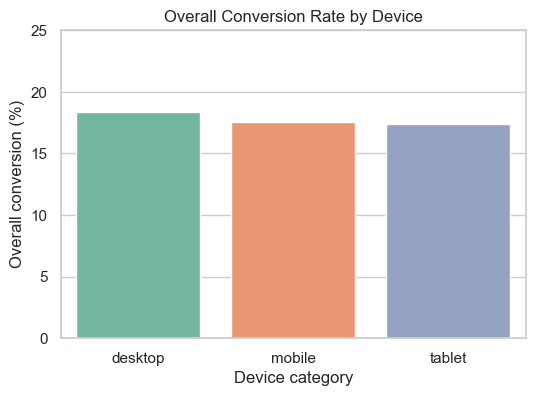

In [14]:
# Engagement of purchasers vs non-purchasers
print("Average engagement by purchase outcome (0 = no purchase, 1 = purchase):")
display(df.groupby('purchase_flag')[['page_views', 'time_on_site_sec']].mean().round(2))

# Funnel performance by device
device_funnel = df.groupby('device_category').agg(
    sessions=('session_id', 'count'),
    carts=('add_to_cart_flag', 'sum'),
    purchases=('purchase_flag', 'sum')
)
device_funnel['Cart Rate (%)'] = device_funnel['carts'] / device_funnel['sessions'] * 100
device_funnel['Cart-to-Purchase (%)'] = device_funnel['purchases'] / device_funnel['carts'] * 100
device_funnel['Overall Conv. (%)'] = device_funnel['purchases'] / device_funnel['sessions'] * 100
print("Funnel performance by device:")
display(device_funnel.round(1))

plt.figure(figsize=(6, 4))
sns.barplot(x=device_funnel.index, y=device_funnel['Overall Conv. (%)'], hue=device_funnel.index,
            palette='Set2', legend=False)
plt.ylabel("Overall conversion (%)")
plt.xlabel("Device category")
plt.title("Overall Conversion Rate by Device")
plt.ylim(0, 25)
plt.show()

## Part 5: Key Findings & Recommendations

### Heatmap interpretation
1. **`add_to_cart_flag` ↔ `purchase_flag` = 0.73 (strong positive).** This is the only strong link to purchasing. Nobody can purchase without first adding to cart, so the cart step is the gateway to revenue.
2. **`page_views` ↔ `purchase_flag` ≈ 0.00 and `time_on_site_sec` ↔ `purchase_flag` ≈ 0.00.** Engagement volume does not predict purchase here. Purchasers and non-purchasers both average about 4.0 page views and about 158 seconds.
3. **`page_views` ↔ `time_on_site_sec` = 0.80.** These two are highly correlated because time was *calculated* from page views. In a real model they would be multicollinear, so use only one of them as a predictor.
4. **`session_start_flag` is NaN** because it never varies.

### Conversion blockers identified
- **Top-of-funnel drop-off (70.6%)**: most sessions never add anything to cart.
- **Cart abandonment (38.4%)**: over a third of shoppers with items still do not buy.
- **Device is not a major blocker**: overall conversion is 18.6% (desktop) vs 17.6% (mobile and tablet), a gap of about 1 percentage point. Mobile is 39% of traffic, so closing even that small gap is worthwhile.

### Recommendations
- Improve product discovery and calls-to-action to lift the 29.4% add-to-cart rate.
- Reduce checkout friction (guest checkout, fewer form fields, clear shipping costs) and use cart-abandonment email/remarketing.
- Do not use "more pages viewed" or "longer sessions" as a proxy for purchase intent without validating it on real data.

### Limitations
- The data is **synthetic**: the near-zero engagement correlations are a result of how it was generated (engagement was simulated independently of purchase). Real GA4 data typically shows more relationship.
- Correlation does not imply causation, and Pearson correlation on 0/1 flags only captures linear association.
- Funnel counts are **sessions**, not unique users (the 5,000 sessions come from about 989 unique `user_id` values).